# Figure 2: GRASS among 21 other open-source packages on a 2.14 billion-cell DEM

This notebook is the supplement to Figure 2 of the paper. It describes how the benchmark was run and computes, from
the measured results in `results/`, the figure, every number the paper cites from it, and every point with the
package behind it. It does not run the benchmark: the timed runs take about five days on a dedicated machine and are
done by the scripts in this folder (see `README.md`).

Contents: data; machine and measurement; operations and settings; selection rules; Figure 2; numbers cited in the
paper; results per operation; repeat runs; agreement; versions.

In [1]:
import csv
import os
import re
import statistics as st
import subprocess
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

RESULTS = Path("results")
runs = pd.read_csv(RESULTS / "runs.tsv", sep="\t", dtype={"memmax": str, "rc": str})
sedona_runs = pd.read_csv(RESULTS / "sedona" / "runs.tsv", sep="\t")
numbers = pd.read_csv(RESULTS / "paper_numbers.csv", dtype=str, keep_default_na=False)
settings = pd.read_csv("settings.csv")
versions = pd.read_csv("versions.csv")
# Figure 2's points: paper_data.py applies the selection rules to the run records (into a temporary directory)
OUT = Path(tempfile.mkdtemp())
subprocess.run([sys.executable, "paper_data.py", str(RESULTS), "ice10", str(OUT)], check=True, capture_output=True,
               env=dict(os.environ, SEDONA_RESULTS=str(RESULTS / "sedona")))
points = pd.read_csv(OUT / "paper_points.csv")
OPS = list(dict.fromkeys(points["op"]))


def table(df, floatfmt=None):
    # a DataFrame as a Markdown table (no extra dependency)
    floatfmt = floatfmt or {}
    cols = list(df.columns)
    fmt = lambda c, v: "" if pd.isna(v) else (floatfmt[c].format(v) if c in floatfmt else str(v))  # noqa: E731
    rows = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    rows += ["| " + " | ".join(fmt(c, v).replace("|", "\\|") for c, v in zip(cols, r)) + " |" for r in df.itertuples(index=False)]
    return Markdown("\n".join(rows))


def nums(*keys):
    # the rows of paper_numbers.csv whose key contains one of the given texts
    return table(numbers[numbers["key"].apply(lambda k: any(x in k for x in keys))])


print(f"{len(runs)} runs in runs.tsv, {len(sedona_runs)} Apache Sedona pipeline steps, {len(points)} points of Figure 2")

265 runs in runs.tsv, 21 Apache Sedona pipeline steps, 115 points of Figure 2


## Data

All operations run on one DEM of Iceland at 10 m: 49,368 × 43,326 = 2,138,917,968 cells, of which 1,060,309,263
(49.6 %) are land and the rest, the sea, is no-data. As Float32 it takes 8.6 GB in memory, the unit of Figure 2's
horizontal axis. `01_data.sh` and `prep_iceland.sh` make all inputs from their public sources.

| Input | Content | Made from |
|---|---|---|
| DEM, 10 m | Float32, NaN no-data; GeoTIFF with deflate, 256 × 256 tiles, BigTIFF; EPSG:3413, ellipsoidal heights | ArcticDEM v4.1 10 m mosaic tiles (Porter et al. 2023, doi:10.7910/DVN/3VDC4W), patched, clipped to the bounding box of the land, masked to the Natural Earth 10 m land polygon; 58,042 void cells (0.005 %) inside the land filled with the nearest valid elevation |
| DEM, 20 m | 24,684 × 21,664 cells, input of the bicubic resampling onto the 10 m grid | Average of the filled 10 m DEM (r.resamp.stats) |
| Series stack | 12 Float32 layers on the 10 m grid, land only | Global irradiation (r.sun, step 0.5 h) for the mid-month days 17, 47, 75, 105, 135, 162, 198, 228, 258, 288, 318, 344, computed at 100 m and interpolated bilinearly onto the 10 m grid |
| Friction | Float32 on the 10 m grid | 1 + slope in degrees / 5 (slope by gdaldem, Horn) |
| Endpoints | Start near Reykjavík (1122385, −2618715), end near Akureyri (1206305, −2388085), EPSG:3413 | Fixed points; as coordinates, points or 0/1 rasters, whichever each package takes |
| Flow directions (accumulation-only comparison) | One conditioned D8 direction raster | Shared by all packages; used only for the agreement check of flow accumulation |

GRASS reads the same data imported into its native format; the other packages read the GeoTIFFs. The sea is no-data
in every input, so tools that allocate a full grid pay for the 2.14 billion-cell rectangle while the computation
covers the 1.06 billion land cells.

## Machine and measurement

Every run used the same 8 cores of one workstation, one run at a time, under a memory limit that ends a run instead
of letting it swap. The state of the machine was recorded at the start of each batch (`results/machine.csv`, one row per batch;
the record of 2026-11-03 holds only the governor, turbo and GRASS version). What was the same in every record:

In [2]:
machine = pd.read_csv(RESULTS / "machine.csv", dtype=str).fillna("")
same = [c for c in machine.columns if (machine[c] != "").sum() > 1 and machine[c][machine[c] != ""].nunique() == 1]
display(pd.DataFrame({"value": [machine[c][machine[c] != ""].iloc[0] for c in same]}, index=same))
print("What differed between the records:")
display(machine.drop(columns=same))

,value
res,ice10
rs_in,ice20
focal,median 25
nthreads,8
pinned_cpus,0-7
xrs_chunk,1024
sig_digits,4
min_cap_s,3600
cpu_model,Intel(R) Xeon(R) W-2295 CPU @ 3.00GHz
logical_cpus,36


What differed between the records:


,record,date,rep,memmax
0,machine_resume_20261102T0816,2026-11-02T08:16:15-0500,,110G
1,machine_nights_20261103,2026-11-03T10:02:13-0500,,
2,machine_resume_20261104T0119,2026-11-04T01:19:10-0500,,110G
3,machine_resume_20261104T1700,2026-11-04T17:00:00-0500,,110G
4,machine_resume_20261104T2101,2026-11-04T21:01:01-0500,,110G
5,machine,2026-11-07T04:36:29-0500,,8555671872
6,machine_r2,2026-11-08T03:19:57-0500,2,110G


| Item | Value |
|---|---|
| CPU | Intel Xeon W-2295, 18 cores, 36 threads; runs pinned to cores 0–7 (taskset), 8 threads or processes for every package that takes a number |
| Frequency | turbo off, performance governor |
| Memory | 125 GB RAM, no swap for the runs |
| Operating system | Ubuntu 24.04.4 LTS, Linux 6.8 |
| Isolation | each run in its own systemd user scope with MemoryMax 110 GB; memory-limit reruns at 1 GB and at the DEM size (7.97 GiB) |
| Idle gate | before each run: 1-minute load below 12 and at least 30 GB available, checked over 60 s |
| Wall time | of the tool process (/usr/bin/time), reading the input and writing the output included |
| Peak memory | peak resident set size of the largest process (/usr/bin/time); for MPI tools (TauDEM) the cgroup peak of the scope; for Apache Sedona the JVM's VmHWM plus the Python driver's |
| Time limit | k × GRASS's fastest time for the operation, k = 10 when GRASS takes up to 0.5 h, 3 from 2 h on, log-linear between, at least 1 h; a run over it is stopped (applied limits below) |
| Repeats | short operations (relief, resampling, slope, algebra, series) two times, a third time where the first two differed by more than 5 %; long operations (flow accumulation, least-cost distance, focal median) once, a sample of them twice; the time of a point is the median of its runs |

Input and output formats: GeoTIFF (deflate, tiled) for the other packages, GRASS's native raster format for GRASS.
Outputs are written to the same local disk. Each package runs as a user would call it: a command-line tool, an R or
Python script, or a Java program, started once per run, so start-up time is included.

The time limits as applied, from GRASS's fastest time per operation (`cap_s` in `paper_data.py`), from
`paper_numbers.csv`:

In [3]:
nums("time limit")

| key | value | how |
|---|---|---|
| flow accumulation \| time limit, h | 5.1 | 8.4 x GRASS's fastest (2207 s) |
| least-cost distance + path \| time limit, h | 5.0 | 9.9 x GRASS's fastest (1824 s) |
| shaded relief \| time limit, h | 1.0 | 19.6 x GRASS's fastest (184 s) |
| resampling, bicubic \| time limit, h | 1.0 | 26.7 x GRASS's fastest (135 s) |
| slope + aspect \| time limit, h | 1.0 | 25.6 x GRASS's fastest (141 s) |
| raster algebra \| time limit, h | 1.0 | 19.3 x GRASS's fastest (187 s) |
| series mean, 12 layers \| time limit, h | 1.0 | 20.2 x GRASS's fastest (178 s) |
| focal median 25 × 25 \| time limit, h | 5.7 | 4.3 x GRASS's fastest (4778 s) |

## Operations and settings

Each package ran its closest equivalent of the GRASS tool with 8 threads or processes where it has a setting for
them, reading and writing compressed GeoTIFF (GRASS: its native format). Common parameters:

- **Flow accumulation**: D8, cell counts, with the package's own depression handling.
- **Least-cost distance + path**: friction 1 + slope/5, from Reykjavík (1122385, −2618715) to Akureyri
  (1206305, −2388085), EPSG:3413.
- **Shaded relief**: azimuth 270°, altitude 30°.
- **Resampling**: bicubic, the 20 m DEM onto the 10 m grid.
- **Slope + aspect**: slope in degrees and aspect.
- **Raster algebra**: with a = |DEM|, the sum over k = 1…8 of sqrt(a + k) × exp(−a / (500 k)), 32 function calls
  per cell, in each package's expression language (`ops_expr.py`).
- **Series mean**: mean of the 12 r.sun layers.
- **Focal median**: 25 × 25 cells.

`settings.csv` gives the tool or function, parameters, memory setting and threads of every run that is a candidate
for a point, by its name in `runs.tsv` (column `run`). Flags: **approximate** (result differs), **incomplete** (a
processing step omitted), **no path** (cost surface without the least-cost path), **user** (user-written in the
package's own mechanism; drawn hollow, counted), **memguard** (the package's own memory check can stop the run), **input doubled** (the DEM is cast to Float64).

**Threads and processes.** Every run is pinned to CPUs 0–7 (`taskset`). `NTHREADS=8` (`config.sh`) is passed to
every setting a package has; a package without a setting runs the operation on one thread. In the runs behind
Figure 2, SAGA, Whitebox Workflows (operations other than flow accumulation), dask and TopoToolbox got their 8 from
the pinning (their default is the number of CPUs they can use) and WhiteboxTools (operations other than flow
accumulation) from its stored value of 8 (WhiteboxTools stores the flags of each call in `WBT/settings.json` and a
call without them uses the stored value); the scripts now pass all of them explicitly. GRASS: `nprocs=8` where a
tool has it (r.resamp.interp, r.slope.aspect, r.mapcalc, r.series, r.neighbors); r.watershed, r.terraflow, r.cost,
r.path and r.relief have no setting. TopoToolbox's operations run almost entirely on one thread (CPU time / wall time
1.0–1.1, shaded relief 2.0); QGIS's algorithms have no setting (`GDAL_NUM_THREADS=8` for output compression only).

**Runs that only trade memory** (candidates of the same point): GDAL with `GDAL_CACHEMAX=64` (and `-wm 64` in
gdalwarp), terra with `terraOptions(todisk = TRUE, memmax = 0.5)`, GeoTools with a 2 GB JAI tile cache, and runs
repeated under the 1 GB and DEM-size memory limits (the memory limit of a run is the `memmax` column of `runs.tsv`).

In [4]:
# every candidate run of the selection rules (paper_data.ops_ice) that is in runs.tsv has a row in settings.csv
sys.argv = ["paper_data.py", str(RESULTS), "ice10", str(OUT)]  # paper_data.py reads its arguments on import
import paper_data  # noqa: E402

ran = set(runs["tool"].str.replace(r"^ops_(grass|other)_", "", regex=True).str.replace(r"_r\d+$", "", regex=True))
cand = {s[2] for spec in paper_data.OPS.values() for s in spec if s[2] in ran or s[2].startswith("sedona_")}
print(f"{len(cand)} candidate runs; without a row in settings.csv: {sorted(cand - set(settings['run'])) or 'none'}; "
      f"rows that are not candidates: {sorted(set(settings['run']) - cand) or 'none'}")

141 candidate runs; without a row in settings.csv: none; rows that are not candidates: none


In [5]:
for op in OPS:
    display(Markdown(f"### {op}"))
    s = settings[settings["operation"] == op].drop(columns="operation")
    display(table(s))

### flow accumulation

| package | run | tool_and_parameters | memory_setting | threads | flags |
|---|---|---|---|---|---|
| GRASS | grass_terraflow_sfd_m500 | r.terraflow -s | memory=500 | one thread (no setting) |  |
| GRASS | r.watershed_m2400_sfd_2560M | r.watershed -m -s (segmented) | memory=2400 | one thread (no setting) |  |
| GRASS | r.watershed_m2400_sfd_3G | r.watershed -m -s (segmented) | memory=2400 | one thread (no setting) |  |
| GRASS | r.watershed_m2400_sfd | r.watershed -m -s (segmented) | memory=2400 | one thread (no setting) |  |
| GRASS | r.watershed_sfd | r.watershed -s (in memory) |  | one thread (no setting) |  |
| TauDEM | traudem_np8 | TauDEM PitRemove -> D8FlowDir -> AreaD8 without edge-contamination check (traudem) |  | 8 MPI processes |  |
| Whitebox Workflows | wbng_d8_natural_t8 | hydrology.depressions_storage.fill_depressions(fix_flats=True, flat_resolution="natural") -> flow_routing.d8_flow_accum(out_type="cells") |  | RAYON_NUM_THREADS=8 |  |
| WhiteboxTools | wbt_d8_t8 | FillDepressions --fix_flats -> D8FlowAccumulation --out_type=cells |  | --max_procs=8 |  |
| RichDEM | richdem_d8_f64_t8 | DEM cast to Float64, FillDepressions + ResolveFlats -> FlowAccumulation(method="D8") | MemoryMax 100 GB | 8 OpenMP threads | input doubled |
| SAGA | saga_ms0.01 | ta_preprocessor 5 (Fill Sinks XXL, Wang & Liu, MINSLOPE=0.01) -> ta_hydrology 0 (top-down, METHOD=0 D8, FLOW_UNIT=0 cells) |  | saga_cmd --cores=8 |  |
| pysheds | pysheds_d8_f64_eps | Float64, fill_pits -> fill_depressions -> resolve_flats(eps=1e-9) -> flowdir(routing="d8") -> accumulation | MemoryMax 100 GB | no setting (one thread) | incomplete |
| pyflwdir | pyflwdir_d8 | pyflwdir.from_dem (priority-flood fill + D8) -> upstream_area(unit="cell") |  | no setting (one thread) |  |
| terra | terra_d8 | terrain(v = "flowdir") -> flowAccumulation (no depression handling) |  | terraOptions(threads = 8, parallel = TRUE) | incomplete |
| TopoToolbox | topotoolbox_d8 | FlowObject (fill + carving through flats) -> flow_accumulation |  | OMP_NUM_THREADS=8 (operations run almost entirely on one thread) |  |
| xarray-spatial | xrs_d8 | Float64, fill -> flow_direction -> flow_accumulation (no flat resolution) |  | NUMBA_NUM_THREADS=8 | incomplete memguard |
| Landlab | fa_cand_landlab_d8 | FlowAccumulator(flow_director="FlowDirectorD8", depression_finder="DepressionFinderAndRouter") |  | no setting (one thread) |  |
| PCRaster | fa_cand_pcraster_d8 | lddcreate removing every pit (outflow depth, core volume, core area and catchment precipitation 1e31) -> accuflux(..., 1) |  | one thread |  |

### least-cost distance + path

| package | run | tool_and_parameters | memory_setting | threads | flags |
|---|---|---|---|---|---|
| GRASS | cost_grass_m300 | r.cost (outdir) -> r.path format=auto raster_path | memory=300 | one thread (no setting) |  |
| GRASS | cost_grass_m20000 | r.cost (outdir) -> r.path format=auto raster_path | memory=20000 | one thread (no setting) |  |
| terra | cost_terra | costDist(friction, target = 0) with the start cell set to 0 |  | terraOptions(threads = 8, parallel = TRUE) | no path |
| SAGA | cost_saga | grid_analysis 0 (accumulated cost, DEST_TYPE=0 points) -> grid_analysis 5 (least-cost paths) |  | saga_cmd --cores=8 |  |
| Whitebox Workflows | cost_wbw_sdat | raster.distance_cost.cost_distance -> cost_pathway, written as SAGA grids (its GeoTIFF writer is classic TIFF, unreadable above 4 GiB) |  | RAYON_NUM_THREADS=8 |  |
| WhiteboxTools | cost_wbt | CostDistance (source raster, accumulation + backlink) -> CostPathway |  | --max_procs=8 |  |
| xarray-spatial | cost_xrs | cost_distance(src, friction, target_values=[1]) + a_star_search(snap_start, snap_goal) (NumPy) |  | NUMBA_NUM_THREADS=8 | memguard |
| raster_tools | cost_rt | distance.cda_cost_distance (cost distance + traceback) |  | dask threaded scheduler, 8 workers | no path |
| scikit-image | cost_skimage | graph.MCP_Geometric(fully_connected=True): find_costs + traceback to the end cell |  | no setting (one thread) |  |
| PCRaster | cost_pcraster | spread(start, 0, friction) |  | one thread | no path |
| gdistance | cost_gdistance | transition(1 / mean, directions = 8) -> geoCorrection(type = "c") -> accCost + shortestPath |  | no setting (one thread) |  |
| pyflwdir | cost_pyflwdir | gis_utils.spread2d (8-neighbour Dijkstra, step length x friction) |  | no setting (one thread) | no path |

### shaded relief

| package | run | tool_and_parameters | memory_setting | threads | flags |
|---|---|---|---|---|---|
| GRASS | relief_grass | r.relief (defaults: altitude 30, azimuth 270) |  | one thread (no setting) |  |
| GDAL | relief_gdal | gdaldem hillshade -az 270 -alt 30 -compute_edges |  | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| GDAL | relief_gdal_cache64 | gdaldem hillshade -az 270 -alt 30 -compute_edges | GDAL_CACHEMAX=64 | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| terra | relief_terra | terrain(c("slope", "aspect"), unit = "radians") -> shade(angle = 30, direction = 270) |  | terraOptions(threads = 8, parallel = TRUE) |  |
| terra | relief_terra_todisk | terrain(c("slope", "aspect"), unit = "radians") -> shade(angle = 30, direction = 270) | terraOptions(todisk = TRUE, memmax = 0.5) | terraOptions(threads = 8, parallel = TRUE) |  |
| SAGA | relief_saga | ta_lighting 0 AZIMUTH=270 DECLINATION=30 |  | saga_cmd --cores=8 |  |
| Whitebox Workflows | relief_wbw | terrain.general.hillshade(azimuth=270, altitude=30) |  | RAYON_NUM_THREADS=8 |  |
| WhiteboxTools | relief_wbt | Hillshade --azimuth=270 --altitude=30 |  | --max_procs=8 |  |
| xarray-spatial | relief_xrs | hillshade(azimuth=270, angle_altitude=30) |  | NUMBA_NUM_THREADS=8 |  |
| xarray-spatial dask | relief_xrsdask | hillshade(azimuth=270, angle_altitude=30), chunks 1024 |  | dask threaded scheduler, 8 workers |  |
| TopoToolbox | relief_tt | GridObject.hillshade(azimuth=270, altitude=30) |  | OMP_NUM_THREADS=8 (operations run almost entirely on one thread) |  |
| QGIS | relief_qgis_v60 | native:hillshade AZIMUTH=270 V_ANGLE=60 (acts as the angle from the zenith: 30 degrees altitude) |  | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| raster_tools | relief_rt | surface.hillshade(azimuth=270, altitude=30) |  | dask threaded scheduler, 8 workers |  |
| xDEM | relief_xdem | DEM.hillshade(surface_fit="Horn", azimuth=0, altitude=30) (xDEM's azimuth 0 gives the others' 270) |  | one process |  |
| xDEM | relief_xdemmp | DEM.hillshade(surface_fit="Horn", azimuth=0, altitude=30), out-of-memory mode (MultiprocConfig, chunk 4096) |  | out-of-memory mode, default cluster (one process) |  |
| xDEM | relief_xdemmpw | DEM.hillshade(surface_fit="Horn", azimuth=0, altitude=30), out-of-memory mode (MultiprocConfig, chunk 4096) |  | out-of-memory mode, 8 worker processes |  |
| Landlab | relief_landlab | calc_hillshade_at_node(alt=30, az=270) |  | no setting (one thread) |  |
| GeoTools | relief_geotools | coverage operation ShadedRelief (jai-ext, altitude 30, azimuth 270, DEFAULT algorithm) |  | JAI tile scheduler |  |
| GeoTools | relief_geotoolspar | coverage operation ShadedRelief (jai-ext, altitude 30, azimuth 270, DEFAULT algorithm), our parallel tile computation | 2 GB JAI tile cache | 8 threads (our parallel tiles) | user |

... (6 outputs left out)

### series mean, 12 layers

| package | run | tool_and_parameters | memory_setting | threads | flags |
|---|---|---|---|---|---|
| GRASS | series_sun_grass_fcell | r.series method=average over FCELL maps |  | nprocs=8 |  |
| GDAL | series_sun_gdal | gdal raster calc (S1 + ... + S12) / 12 |  | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| GDAL | series_sun_gdal_cache64 | gdal raster calc (S1 + ... + S12) / 12 | GDAL_CACHEMAX=64 | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| terra | series_sun_terra | mean(rast(files)) |  | terraOptions(threads = 8, parallel = TRUE) |  |
| terra | series_sun_terra_todisk | mean(rast(files)) | terraOptions(todisk = TRUE, memmax = 0.5) | terraOptions(threads = 8, parallel = TRUE) |  |
| SAGA | series_sun_saga | statistics_grid 4 MEAN |  | saga_cmd --cores=8 |  |
| Whitebox Workflows | series_sun_wbw_bigtiff_b | raster.average_overlay, written as BigTIFF (its default classic TIFF is unreadable above 4 GiB) |  | RAYON_NUM_THREADS=8 |  |
| WhiteboxTools | series_sun_wbt | AverageOverlay |  | --max_procs=8 |  |
| xarray-spatial | series_sun_xrs | xr.concat(layers, "t").mean("t") |  | NUMBA_NUM_THREADS=8 |  |
| xarray-spatial dask | series_sun_xrsdask | xr.concat(layers, "t").mean("t"), chunks 1024 |  | dask threaded scheduler, 8 workers |  |
| QGIS | series_sun_qgis | native:cellstatistics STATISTIC=2 (mean) |  | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| Sedona | sedona_series | RS_Union stack + Jiffle, GDAL tiles and mosaic |  | Spark local mode, 8 cores | user |
| raster_tools | series_sun_rt | general.local_stats(band_concat(files), "mean") |  | dask threaded scheduler, 8 workers |  |
| xDEM | series_sun_xdem | sum of GeoUtils Rasters / 12 |  | one process |  |
| PCRaster | series_sun_pcraster | sum of maps / 12 |  | one thread |  |
| Orfeo ToolBox | series_sun_otb | otbcli_BandMath -exp "(im1b1+...+im12b1)/12" |  | ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=8 |  |
| GeoTools | series_sun_geotools | Jiffle script |  | JAI tile scheduler |  |

### focal median 25 × 25

| package | run | tool_and_parameters | memory_setting | threads | flags |
|---|---|---|---|---|---|
| GRASS | focal_grass_n8 | r.neighbors size=25 method=median |  | nprocs=8 |  |
| GDAL | focal_gdal | gdal raster neighbors --method median --kernel equal --size 25 |  | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| GDAL | focal_gdal_cache64 | gdal raster neighbors --method median --kernel equal --size 25 | GDAL_CACHEMAX=64 | no setting (one thread); GDAL_NUM_THREADS=8 for compression |  |
| terra | focal_terra | focal(w = 25, fun = "median", na.rm = TRUE); the unlimited run of 2026-11-02 used na.rm = FALSE (same values on land; no value where the window touches no-data) |  | terraOptions(threads = 8, parallel = TRUE) |  |
| terra | focal_terra_todisk | focal(w = 25, fun = "median") | terraOptions(todisk = TRUE, memmax = 0.5) | terraOptions(threads = 8, parallel = TRUE) |  |
| terra | focal_terra_narm | focal(w = 25, fun = "median", na.rm = TRUE) |  | terraOptions(threads = 8, parallel = TRUE) |  |
| SAGA | focal_saga | statistics_grid 1 MEDIAN, square kernel, radius 12 |  | saga_cmd --cores=8 |  |
| Whitebox Workflows | focal_wbw | remote_sensing.filters.median_filter(25, 25, sig_digits=4) (histogram median) |  | RAYON_NUM_THREADS=8 | approximate |
| WhiteboxTools | focal_wbt | MedianFilter --filterx=25 --filtery=25 --sig_digits=4 (histogram median) |  | --max_procs=8 | approximate |
| xarray-spatial | focal_xrs | focal.apply with a numba nanmedian kernel (no median in focal_stats) |  | NUMBA_NUM_THREADS=8 | user |
| xarray-spatial dask | focal_xrsdask | focal.apply with a numba nanmedian kernel (no median in focal_stats), chunks 1024 |  | dask threaded scheduler, 8 workers | user |
| TopoToolbox | focal_tt | GridObject.filter(method="median", kernelsize=25) |  | OMP_NUM_THREADS=8 (operations run almost entirely on one thread) |  |
| raster_tools | focal_rt | focal.focal(r, "median", 25, 25, ignore_null=True) |  | dask threaded scheduler, 8 workers |  |
| xDEM | focal_xdem | DEM.filter("median", size=25) |  | one process |  |
| scikit-image | focal_skimage | filters.median(footprint 25 x 25, behavior="ndimage") (no no-data handling) |  | no setting (one thread) | approximate |
| GeoTools | focal_geotools | coverage operation MedianFilter (25 x 25) |  | JAI tile scheduler | approximate |
| Orfeo ToolBox | focal_otb | otbcli_BandMathX -exp "median(im1b1N21x21)" (21 x 21, BandMathX's largest window) |  | ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=8 | approximate |
| GeoTools | focal_geotoolspar | coverage operation MedianFilter (25 x 25), our parallel tile computation | 2 GB JAI tile cache | 8 threads (our parallel tiles) | user approximate |

## Selection rules

Each package gets one point per operation, chosen by rule from its runs (`paper_data.py`); the same rules apply to
GRASS and the others, and none depends on how a package compares.

- **Candidate runs** of a package and operation: its repeats, its reruns under the 1 GB and DEM-size memory limits,
  settings that only trade memory for time (GDAL with a 64 MB block cache, terra with todisk), and the same functions
  run on more threads or processes (pcraster.multicore, xDEM's out-of-memory mode on 8 worker processes).
- **Time of a run** = the median over its repeats.
- **Main point** = the run with the least peak memory among those within 5 % of the package's fastest run.
- **Linked point** = a slower run of the same package that needs at most half the memory of the point it is linked
  to (for GRASS flow accumulation a chain: r.watershed -s, then r.watershed -m, then r.terraflow). It is drawn small
  and linked, and it is not counted in the median.
- **Median and band** = the median and the interquartile range of all packages' main points, GRASS's included. Time
  is divided by the median time, memory by the DEM's in-memory size (8.6 GB).
- **Hollow points** count in the median and are marked: an approximate result, an omitted step, or a user-written
  implementation in the package's own mechanism (a standard function passed to its focal operator, its documented
  tiling, its operations run on threads).
- **Did not finish**: a run stopped at the time limit, the memory limit, the package's own memory check or an error
  is not drawn; the panel's lower right corner counts them by reason.
- **GRASS** shows each of its configurations (tools or memory settings for the same operation) as a green point,
  linked; the ratio quoted for GRASS is its fastest configuration.
- **Two backends** of one package (xarray-spatial on NumPy and on dask) are two points.

## Figure 2

`paper_data.py` applies the selection rules to `runs.tsv` and writes Figure 2's points and the numbers the paper
cites (`paper_numbers.csv`); `make_p1.py` draws the figure from them (`04_figure.sh`). The notebook ran
`paper_data.py` when it started; this cell checks that the numbers equal the published ones and draws the figure.

paper_numbers.csv rebuilt from runs.tsv: identical


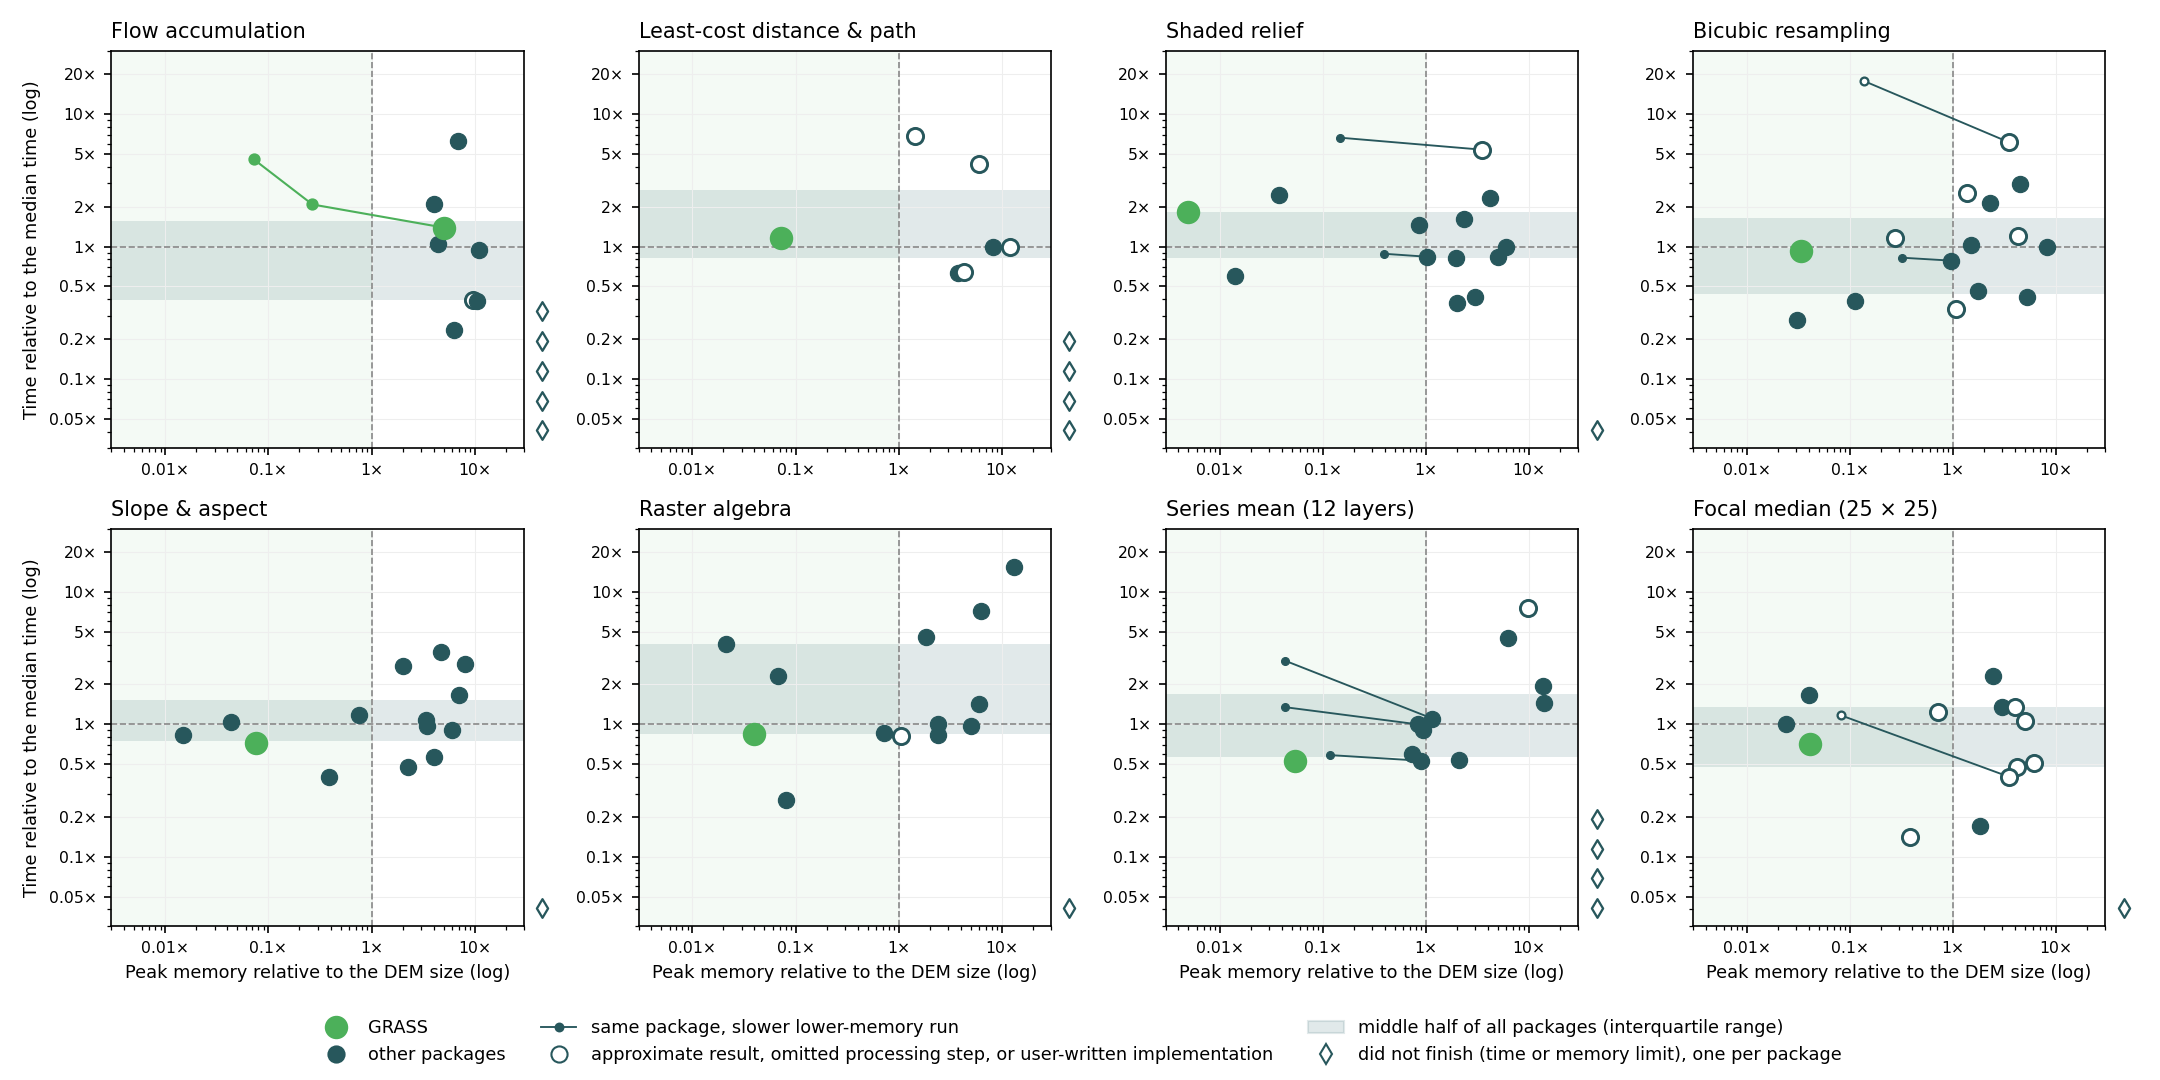

In [6]:
same = (OUT / "paper_numbers.csv").read_bytes() == (RESULTS / "paper_numbers.csv").read_bytes()
print("paper_numbers.csv rebuilt from runs.tsv:", "identical" if same else "DIFFERENT")
subprocess.run([sys.executable, "make_p1.py", str(OUT), str(OUT)], check=True, capture_output=True,
               env=dict(os.environ, MPLCONFIGDIR=tempfile.mkdtemp()))
Image(filename=str(OUT / "figure-benchmark.png"))

## Numbers cited in the paper

Each sentence of the paper with the numbers behind it, from `results/paper_numbers.csv`. Times are relative to the
median time of all packages' main points, GRASS included; memory is relative to the DEM in memory
(`dem_in_memory_GiB`, the unit of the ratios; the paper gives the size as 8.6 GB).

"The benchmark compares GRASS and 21 other open-source packages … on an Iceland DEM of 2.14 billion cells":

In [7]:
nums("dem_", "other_packages")

| key | value | how |
|---|---|---|
| dem_cells | 2138917968 | 49,368 x 43,326 |
| dem_in_memory_GB | 8.56 | cells x 4 bytes (Float32), 10^9 bytes |
| dem_in_memory_GiB | 7.968 | cells x 4 bytes, 2^30 bytes: the unit of the memory ratios |
| other_packages | 21 | with a point or a run that did not finish (xarray-spatial on NumPy and on dask counted once): GDAL, gdistance, GeoTools, Landlab, Orfeo ToolBox, PCRaster, pyflwdir, pysheds, QGIS, raster_tools, RichDEM, SAGA, scikit-image, Sedona, TauDEM, terra, TopoToolbox, Whitebox Workflows, WhiteboxTools, xarray-spatial, xDEM |

"GRASS performed about as fast as other packages (0.5–1.8 times the median time of all packages in every
operation)":

In [8]:
nums("GRASS fastest")

| key | value | how |
|---|---|---|
| flow accumulation \| GRASS fastest \| time / median | 1.388 | r.watershed -s |
| least-cost distance + path \| GRASS fastest \| time / median | 1.152 | memory=300 |
| shaded relief \| GRASS fastest \| time / median | 1.822 | r.relief |
| resampling, bicubic \| GRASS fastest \| time / median | 0.927 | memory=300 |
| slope + aspect \| GRASS fastest \| time / median | 0.72 | r.slope.aspect |
| raster algebra \| GRASS fastest \| time / median | 0.84 | r.mapcalc |
| series mean, 12 layers \| GRASS fastest \| time / median | 0.527 | r.series |
| focal median 25 × 25 \| GRASS fastest \| time / median | 0.71 | r.neighbors |
| GRASS fastest \| time / median \| range | 0.53-1.82 | over the 8 operations |

"… and used less memory than the DEM size. Most other packages needed more memory than the DEM (per-operation
medians of 1.6 to 7 times its size), while GRASS needed less than a tenth of it":

In [9]:
nums("GRASS main point", "other packages")

| key | value | how |
|---|---|---|
| flow accumulation \| GRASS main point \| memory / DEM | 5.092 | r.watershed -s |
| least-cost distance + path \| GRASS main point \| memory / DEM | 0.073 | memory=300 |
| shaded relief \| GRASS main point \| memory / DEM | 0.005 | r.relief |
| resampling, bicubic \| GRASS main point \| memory / DEM | 0.034 | memory=300 |
| slope + aspect \| GRASS main point \| memory / DEM | 0.075 | r.slope.aspect |
| raster algebra \| GRASS main point \| memory / DEM | 0.04 | r.mapcalc |
| series mean, 12 layers \| GRASS main point \| memory / DEM | 0.054 | r.series |
| focal median 25 × 25 \| GRASS main point \| memory / DEM | 0.041 | r.neighbors |
| GRASS main point \| memory / DEM \| largest outside flow accumulation | 0.075 | below 0.1: less than a tenth |
| flow accumulation \| other packages \| median memory / DEM | 6.95 | 7 main points |
| flow accumulation \| other packages \| main points at or above the DEM size | 7 of 7 |  |
| least-cost distance + path \| other packages \| median memory / DEM | 5.16 | 6 main points |
| least-cost distance + path \| other packages \| main points at or above the DEM size | 6 of 6 |  |
| shaded relief \| other packages \| median memory / DEM | 2.17 | 12 main points |
| shaded relief \| other packages \| main points at or above the DEM size | 9 of 12 |  |
| resampling, bicubic \| other packages \| median memory / DEM | 1.62 | 14 main points |
| resampling, bicubic \| other packages \| main points at or above the DEM size | 10 of 14 |  |
| slope + aspect \| other packages \| median memory / DEM | 3.38 | 13 main points |
| slope + aspect \| other packages \| main points at or above the DEM size | 9 of 13 |  |
| raster algebra \| other packages \| median memory / DEM | 2.12 | 12 main points |
| raster algebra \| other packages \| main points at or above the DEM size | 8 of 12 |  |
| series mean, 12 layers \| other packages \| median memory / DEM | 1.63 | 10 main points |
| series mean, 12 layers \| other packages \| main points at or above the DEM size | 6 of 10 |  |
| focal median 25 × 25 \| other packages \| median memory / DEM | 2.74 | 12 main points |
| focal median 25 × 25 \| other packages \| main points at or above the DEM size | 8 of 12 |  |
| other packages \| median memory / DEM \| range | 1.62-6.95 | over the 8 operations |
| other packages \| main points at or above the DEM size | 63 of 86 | all operations |

"Flow accumulation was the one operation that required a choice between speed and memory: the fastest GRASS tool
needed five times the memory of the DEM, while the low-memory tools needed about a quarter of it or less at 2 to 5
times the median time":

In [10]:
nums("flow accumulation | GRASS r.")

| key | value | how |
|---|---|---|
| flow accumulation \| GRASS r.watershed -s \| time / median | 1.388 |  |
| flow accumulation \| GRASS r.watershed -s \| memory / DEM | 5.092 |  |
| flow accumulation \| GRASS r.watershed -m memory=2400 \| time / median | 2.08 |  |
| flow accumulation \| GRASS r.watershed -m memory=2400 \| memory / DEM | 0.267 |  |
| flow accumulation \| GRASS r.terraflow memory=500 \| time / median | 4.562 |  |
| flow accumulation \| GRASS r.terraflow memory=500 \| memory / DEM | 0.072 |  |

"All GRASS operations were also able to complete under a 1 GB memory limit" (series ran without a limit and peaked
below 1 GB):

In [11]:
nums("within 1 GB")

| key | value | how |
|---|---|---|
| flow accumulation \| GRASS within 1 GB | 1 GiB limit | grass_terraflow_sfd_m500, 8405 s |
| least-cost distance + path \| GRASS within 1 GB | 1 GiB limit | cost_grass_m300, 2476 s |
| shaded relief \| GRASS within 1 GB | 1 GiB limit | relief_grass, 184 s |
| resampling, bicubic \| GRASS within 1 GB | 1 GiB limit | resample_grass_m300_n8, 135 s |
| slope + aspect \| GRASS within 1 GB | 1 GiB limit | slope_grass_n8, 143 s |
| raster algebra \| GRASS within 1 GB | 1 GiB limit | algebra_grass_n8, 187 s |
| series mean, 12 layers \| GRASS within 1 GB | no limit, peak 0.43 GiB | series_sun_grass_fcell |
| focal median 25 × 25 \| GRASS within 1 GB | 1 GiB limit | focal_grass_n8, 4778 s |

"Short operations were run at least twice per package, while longer operations … were run only once due to time
constraints. A sample of the longer runs was repeated to check agreement. Runs were restricted to a time limit of
one hour for short operations and at least four times GRASS's fastest runtime for long operations. Runs were also
restricted to a memory limit of 100–125 GB or packages' internal memory checks":

In [12]:
nums("short operations", "long operations", "time limit", "did not finish")

| key | value | how |
|---|---|---|
| flow accumulation \| time limit, h | 5.1 | 8.4 x GRASS's fastest (2207 s) |
| least-cost distance + path \| time limit, h | 5.0 | 9.9 x GRASS's fastest (1824 s) |
| shaded relief \| time limit, h | 1.0 | 19.6 x GRASS's fastest (184 s) |
| resampling, bicubic \| time limit, h | 1.0 | 26.7 x GRASS's fastest (135 s) |
| slope + aspect \| time limit, h | 1.0 | 25.6 x GRASS's fastest (141 s) |
| raster algebra \| time limit, h | 1.0 | 19.3 x GRASS's fastest (187 s) |
| series mean, 12 layers \| time limit, h | 1.0 | 20.2 x GRASS's fastest (178 s) |
| focal median 25 × 25 \| time limit, h | 5.7 | 4.3 x GRASS's fastest (4778 s) |
| did not finish \| memory limits, GiB | 100, 110, 125 | 11 runs (MemoryMax, the machine's RAM without one, or the package's own memory check); 6 runs at the time limit |
| short operations \| fewest runs without a memory limit per package | 2 | over the 66 points of the short operations |
| long operations \| repeated runs | 8 | cost_grass_m300, focal_gdal, focal_grass_n8, grass_terraflow_sfd_m500, pyflwdir_d8, r.watershed_m2400_sfd, r.watershed_sfd, wbt_d8_t8 |
| long operations \| repeated runs \| largest difference, % | 2.5 | (slowest - fastest) / median |

## Results per operation

Every point of Figure 2 by name, sorted by time. Time is the median over the runs in the `n` column; memory is the
peak. The ratio columns are what Figure 2 plots. A linked point (↳) is the package's slower lower-memory run. Then the runs that did not finish, with the reason and the limit.

In [13]:
sv = lambda x: x if isinstance(x, str) else ""  # noqa: E731
for op in OPS:
    p = points[points["op"] == op]
    g0 = p[(p["package"] == "GRASS") & (p["fig"] == "main")].iloc[0]
    n_all = int(((p["status"] == "ok") & (p["fig"] == "main")).sum())
    display(Markdown(f"### {op}\n\nMiddle half of all {n_all} packages' main points, GRASS included: "
                     f"{g0['all_q1']:.2f}–{g0['all_q3']:.2f}× the median."))
    rows = []
    for r in p[p["status"] == "ok"].itertuples():
        rows.append((r.wall_s, [r.package, r.name, r.wall_s, r.mem_GB, r.time_per_median, r.mem_per_dem, r.n,
                                ", ".join(x for x in [sv(r.fig) if sv(r.fig) != "main" else "", sv(r.flags)] if x)]))
        if isinstance(r.alt_name, str):
            rows.append((r.alt_wall_s, ["↳ " + r.package, r.alt_name, r.alt_wall_s, r.alt_mem_GB, r.alt_time_per_median,
                                        r.alt_mem_per_dem, None, ", ".join(x for x in ["linked", sv(r.alt_flags)] if x)]))
    rows.sort(key=lambda t: t[0])
    df = pd.DataFrame([r for _, r in rows], columns=["package", "run", "time (s)", "peak memory (GB)", "time / median",
                                                     "memory / DEM", "n", "marker"])
    display(table(df, {"time (s)": "{:.0f}", "peak memory (GB)": "{:.2f}", "time / median": "{:.2f}",
                       "memory / DEM": "{:.3f}", "n": "{:.0f}"}))
    d = p[p["status"] == "dnf"]
    if len(d):
        display(Markdown("Did not finish:"))
        d = d.assign(mem_reached_GB=d["mem_reached_GB"].where(d["mem_reached_GB"] > 0))
        display(table(d[["package", "name", "reason", "mem_reached_GB", "limit_GB", "cap_s"]].rename(
            columns={"name": "run", "mem_reached_GB": "memory reached (GB)", "limit_GB": "memory limit (GB)",
                     "cap_s": "time limit (s)"}), {"memory reached (GB)": "{:.1f}", "memory limit (GB)": "{:.0f}",
                                                    "time limit (s)": "{:.0f}"}))

### flow accumulation

Middle half of all 8 packages' main points, GRASS included: 0.39–1.56× the median.

| package | run | time (s) | peak memory (GB) | time / median | memory / DEM | n | marker |
|---|---|---|---|---|---|---|---|
| Whitebox Workflows | wbng_d8_natural_t8 | 370 | 49.86 | 0.23 | 6.257 | 1 |  |
| TopoToolbox | topotoolbox_d8 | 620 | 83.96 | 0.39 | 10.537 | 1 |  |
| terra | terra_d8 | 628 | 77.37 | 0.40 | 9.710 | 1 | incomplete |
| pyflwdir | pyflwdir_d8 | 1509 | 88.31 | 0.95 | 11.083 | 2 |  |
| WhiteboxTools | wbt_d8_t8 | 1672 | 34.93 | 1.05 | 4.384 | 2 |  |
| GRASS | r.watershed_sfd | 2207 | 40.57 | 1.39 | 5.092 | 2 |  |
| GRASS | r.watershed_m2400_sfd | 3308 | 2.13 | 2.08 | 0.267 | 2 | alt |
| SAGA | saga_ms0.01 | 3332 | 31.97 | 2.10 | 4.012 | 1 |  |
| GRASS | grass_terraflow_sfd_m500 | 7256 | 0.57 | 4.56 | 0.072 | 2 | alt |
| TauDEM | traudem_np8 | 9891 | 55.35 | 6.22 | 6.946 | 1 |  |

Did not finish:

| package | run | reason | memory reached (GB) | memory limit (GB) | time limit (s) |
|---|---|---|---|---|---|
| RichDEM | richdem_d8_f64_t8 | memory limit |  | 100 |  |
| pysheds | pysheds_d8_f64_eps | memory limit |  | 100 |  |
| xarray-spatial | xrs_d8 | memory limit | 33.7 | 110 |  |
| Landlab | fa_cand_landlab_d8 | memory limit |  | 110 |  |
| PCRaster | fa_cand_pcraster_d8 | time limit | 36.5 | 110 | 18489 |

### least-cost distance + path

Middle half of all 7 packages' main points, GRASS included: 0.82–2.67× the median.

| package | run | time (s) | peak memory (GB) | time / median | memory / DEM | n | marker |
|---|---|---|---|---|---|---|---|
| Whitebox Workflows | cost_wbw_sdat | 995 | 29.94 | 0.63 | 3.757 | 1 |  |
| pyflwdir | cost_pyflwdir | 1019 | 34.11 | 0.64 | 4.281 | 1 | no path |
| WhiteboxTools | cost_wbt | 1576 | 65.01 | 1.00 | 8.159 | 1 |  |
| raster_tools | cost_rt | 1583 | 95.86 | 1.00 | 12.030 | 1 | no path |
| GRASS | cost_grass_m300 | 1824 | 0.58 | 1.15 | 0.073 | 2 |  |
| GRASS | cost_grass_m20000 | 1845 | 19.92 | 1.17 | 2.500 | 1 |  |
| PCRaster | cost_pcraster | 6625 | 48.19 | 4.19 | 6.048 | 1 | no path |
| terra | cost_terra | 10797 | 11.45 | 6.82 | 1.437 | 1 | no path |

... (20 outputs left out)

### focal median 25 × 25

Middle half of all 13 packages' main points, GRASS included: 0.47–1.36× the median.

| package | run | time (s) | peak memory (GB) | time / median | memory / DEM | n | marker |
|---|---|---|---|---|---|---|---|
| xarray-spatial dask | focal_xrsdask | 948 | 3.08 | 0.14 | 0.387 | 1 | user |
| raster_tools | focal_rt | 1153 | 14.76 | 0.17 | 1.852 | 1 |  |
| GeoTools | focal_geotoolspar | 2709 | 27.90 | 0.40 | 3.501 | 1 | user approximate |
| Whitebox Workflows | focal_wbw | 3189 | 33.22 | 0.47 | 4.169 | 1 | approximate |
| WhiteboxTools | focal_wbt | 3458 | 48.89 | 0.51 | 6.136 | 1 | approximate |
| GRASS | focal_grass_n8 | 4778 | 0.33 | 0.71 | 0.041 | 1 |  |
| GDAL | focal_gdal_cache64 | 6732 | 0.19 | 1.00 | 0.024 | 1 |  |
| xarray-spatial | focal_xrs | 7162 | 40.16 | 1.06 | 5.040 | 1 | user |
| ↳ GeoTools | focal_geotools | 7853 | 0.66 | 1.17 | 0.083 |  | linked, approximate |
| Orfeo ToolBox | focal_otb | 8316 | 5.72 | 1.24 | 0.718 | 1 | approximate |
| scikit-image | focal_skimage | 9135 | 32.01 | 1.36 | 4.017 | 1 | approximate |
| TopoToolbox | focal_tt | 9136 | 24.12 | 1.36 | 3.027 | 1 |  |
| terra | focal_terra_todisk | 11196 | 0.32 | 1.66 | 0.040 | 1 |  |
| SAGA | focal_saga | 15598 | 19.56 | 2.32 | 2.455 | 1 |  |

Did not finish:

| package | run | reason | memory reached (GB) | memory limit (GB) | time limit (s) |
|---|---|---|---|---|---|
| xDEM | focal_xdem | time limit | 84.6 | 110 | 20466 |

## Repeat runs

Short operations ran twice, and a third time where the first two differed by more than 5 %. Long operations ran
once, and a sample of them was repeated to check that one run is enough. Every repeat in `runs.tsv` (same run name
and memory limit, tags `_r2`, `_r3`) against the first run:

In [14]:
ok = runs[runs["rc"].astype(str) == "0"].copy()
ok["base"] = ok["tool"].str.replace(r"^ops_(grass|other)_", "", regex=True)
ok["rep"] = ok["base"].str.extract(r"_r(\d+)$")[0].fillna(1).astype(int)
ok["base"] = ok["base"].str.replace(r"_r\d+$", "", regex=True)
pairs = []
for (b, mm), grp in ok.sort_values(["rep", "time"]).groupby(["base", "memmax"]):
    if len(grp) > 1:
        first = grp.iloc[0]["wall_s"]
        pairs += [(b, mm, first, w, w / first) for w in grp.iloc[1:]["wall_s"]]
pairs = pd.DataFrame(pairs, columns=["run", "memmax", "first (s)", "repeat (s)", "ratio"])


def summ(df, label):
    r = df["ratio"]
    return {"repeat pairs": label, "pairs": len(r), "median ratio": r.median(),
            "within ±5 %": int(((r - 1).abs() <= 0.05).sum()), "within ±10 %": int(((r - 1).abs() <= 0.10).sum())}


table(pd.DataFrame([summ(pairs, "all"), summ(pairs[pairs["first (s)"] >= 1000], "first run 1000 s or longer")]),
      {"median ratio": "{:.3f}"})

| repeat pairs | pairs | median ratio | within ±5 % | within ±10 % |
|---|---|---|---|---|
| all | 90 | 1.003 | 70 | 80 |
| first run 1000 s or longer | 15 | 0.998 | 13 | 13 |

In [15]:
table(pairs[pairs["first (s)"] >= 1000].assign(difference=lambda d: (d["ratio"] - 1) * 100)
      .drop(columns="ratio").sort_values("run"), {"first (s)": "{:.0f}", "repeat (s)": "{:.0f}", "difference": "{:+.1f} %"})

| run | memmax | first (s) | repeat (s) | difference |
|---|---|---|---|---|
| algebra_geotools | 110G | 1018 | 1016 | -0.2 % |
| algebra_wbw | 110G | 1588 | 1604 | +1.0 % |
| algebra_xdem | 110G | 2852 | 3495 | +22.5 % |
| algebra_xdem | 110G | 2852 | 3408 | +19.5 % |
| cost_grass_m300 | 110G | 1836 | 1812 | -1.3 % |
| focal_gdal | 110G | 6765 | 6790 | +0.4 % |
| focal_grass_n8 | 110G | 4810 | 4892 | +1.7 % |
| grass_terraflow_sfd_m500 | 110G | 7259 | 7252 | -0.1 % |
| pyflwdir_d8 | 110G | 1511 | 1506 | -0.3 % |
| r.watershed_m2400_sfd | 110G | 3349 | 3266 | -2.5 % |
| r.watershed_sfd | 110G | 2209 | 2205 | -0.2 % |
| resample_geotools | 110G | 2636 | 2525 | -4.2 % |
| resample_geotools_c2g | 110G | 1110 | 1107 | -0.2 % |
| series_sun_wbt | infinity | 1528 | 1523 | -0.3 % |
| wbt_d8_t8 | 110G | 1679 | 1665 | -0.8 % |

The long pairs outside ±5 % are xDEM raster algebra: its first run was faster than the two later runs, which agree
with each other within 2.5 %; the point is the median of the three. The paper's ranges (0.5–1.8× the median time,
the memory medians) are the measured values; the repeat differences above show how far a further run could move
them.

## Agreement

Every result was compared with a reference on the interior land cells (2 cells in from the data edge; 14 for the
25 × 25 median) by `03_checks.sh`; its outputs are in `results/agreement/`. The packages agree within float32
rounding except for the model differences listed; those are drawn as approximate where they change values.

| Operation | Reference | Measure | Agreement | Differences |
|---|---|---|---|---|
| raster algebra | GDAL, and a float64 computation | mean and maximum difference | all within 3.1e-5 | none |
| series mean | GDAL | mean and maximum difference | identical; raster_tools and xarray-spatial dask within 7e-4, Whitebox Workflows (Float64 output) within 1.2e-4 | none |
| shaded relief | GDAL | correlation of the shading | ≥ 0.993; raster_tools, xDEM, GeoTools ≥ 0.9999 | QGIS V_ANGLE acts as the angle from the zenith, so the run uses 60 for a 30° sun |
| slope + aspect | GDAL | mean difference of slope and of aspect (circular) | GDAL, terra, SAGA, xarray-spatial, RichDEM, raster_tools, xDEM, PCRaster within 2e-5° | Whitebox mean 0.17°, TopoToolbox 0.05° (other edge and gradient formulas) |
| resampling | GDAL | mean and maximum difference | GDAL, terra, SAGA, xarray-spatial, xDEM identical; Apache Sedona within 0.0035 m on 99.9 % of cells | approximate: raster_tools within 4 cells of its dask chunk seams (0.06 % of cells, up to 9.9 m); Orfeo ToolBox and GeoTools only next to no-data; scikit-image a spline (mean 0.6 m); xarray-spatial dask (odc-geo) 0.4 % of cells. Whitebox shifted half a source cell; TopoToolbox grid 2 rows taller |
| focal median 25 × 25 | GDAL | mean and maximum difference | GDAL, SAGA, xarray-spatial, raster_tools identical; terra identical but 1.95 M land cells without value | approximate: Whitebox histogram median (mean 0.04 m, max 24.7 m); scikit-image and GeoTools only next to no-data (their kernels do not skip it); Orfeo ToolBox a 21 × 21 window (mean 0.38 m, max 94 m from the 25 × 25 median); TopoToolbox mean 0.006 m, 33.6 k cells without value |
| least-cost distance | GRASS r.cost | correlation | 1.0000 for WhiteboxTools, terra, Whitebox Workflows, raster_tools, PCRaster, pyflwdir | none (Whitebox Workflows' point is its run that writes SAGA grids: its default GeoTIFF is classic TIFF, unreadable above 4 GiB) |
| flow accumulation (accumulation only) | pyflwdir | share of equal cells, largest count | maximum 80,767,968 cells for pyflwdir, terra, WhiteboxTools, Whitebox Workflows; GRASS 80,767,939 | GRASS leaves the 79,532 cells with direction 0 null; TauDEM drops the 2.2 M cells (0.2 %) whose path ends in one; Whitebox Workflows accumulates in the direction raster's type |

The whole-workflow flow accumulation differs between packages by design (depression and flat handling), so it is
compared only on the shared direction raster.

In [16]:
for f in sorted((RESULTS / "agreement").glob("*.txt")):
    print(f"== {f.name}")
    print(f.read_text().strip())

== agree_added_ice10.txt
relief   rt        |r| 1.0000; no value on 0.00% of the reference's interior cells
slope    rt        mean |d| 3.332e-07, max 1.129e-05; aspect mean |d| 5.33e-06 (|d| > 90: 0.0%); no value on 0.00% of the reference's interior cells
focal    rt        mean |d| 0, max 0; no value on 0.00% of the reference's interior cells
algebra  rt        mean |d| 0, max 0; no value on 0.00% of the reference's interior cells
resample rt        mean |d| 0.0001361, max 9.86; no value on 0.00% of the reference's interior cells
cost     rt        |r| 1.0000, median 10.0000 of ref; no value on 0.00% of the reference's interior cells
slope    xdem      mean |d| 6.312e-07, max 1.526e-05; aspect mean |d| 1.04e-05 (|d| > 90: 0.0%); no value on 0.00% of the reference's interior cells
algebra  xdem      mean |d| 3.072e-06, max 7.629e-06; no value on 0.00% of the reference's interior cells
resample xdem      mean |d| 0, max 0; no value on 0.00% of the reference's interior cells
relief   xd

## Versions

`versions.csv` is generated by `versions.py` from the files that install the software (`envs/`, `00_envs.sh`) and
from `results/machine.csv`. Not in it: the operating system, Ubuntu 24.04.4 LTS, and Java, OpenJDK 21 from Ubuntu
(GeoTools, Apache Sedona).

In [17]:
table(versions)

| package | version | environment | source | note |
|---|---|---|---|---|
| Python | 3.14.8 | qgis | envs/mamba_qgis.txt |  |
| GDAL | 3.13.3 | qgis | envs/mamba_qgis.txt |  |
| QGIS | 4.2.3 | qgis | envs/mamba_qgis.txt |  |
| GDAL library | 3.13.3 | r | envs/mamba_r.txt |  |
| R | 4.5.3 | r | envs/mamba_r.txt |  |
| terra | 1.9-50 | r | envs/mamba_r.txt |  |
| MPICH | 4.3.1 | taudem | envs/mamba_taudem.txt |  |
| TauDEM | 5.3.8 | taudem | envs/mamba_taudem.txt |  |
| R | 4.5.3 | gdistance | envs/mamba_gdistance.txt |  |
| sp (R) | 2.2-3 | gdistance | envs/mamba_gdistance.txt |  |
| raster (R) | 3.6-32 | gdistance | envs/mamba_gdistance.txt |  |
| gdistance | 1.6.5 | gdistance | envs/mamba_gdistance.txt |  |
| Python | 3.11.17 | richdem | envs/mamba_richdem.txt |  |
| RichDEM | 2.4.3 | richdem | envs/mamba_richdem.txt |  |
| Python | 3.12.16 | pcraster | envs/mamba_pcraster.txt |  |
| PCRaster | 4.4.3 | pcraster | envs/mamba_pcraster.txt |  |
| numba | 0.68.0 | .venv | envs/pip_venv.txt |  |
| NumPy | 2.3.5 | .venv | envs/pip_venv.txt |  |
| pyflwdir | 0.5.12 | .venv | envs/pip_venv.txt |  |
| pysheds | 0.5 | .venv | envs/pip_venv.txt |  |
| rasterio | 1.5.2 | .venv | envs/pip_venv.txt |  |
| scikit-image | 0.26.0 | .venv | envs/pip_venv.txt |  |
| SciPy | 1.18.1 | .venv | envs/pip_venv.txt |  |
| whitebox (Python wrapper of WhiteboxTools) | 2.3.6 | .venv | envs/pip_venv.txt |  |
| Python | 3.12.3 | .venv | envs/python_venv.txt |  |
| Whitebox Workflows | 2.0.6 | .venv-wbng | envs/pip_venv-wbng.txt |  |
| Python | 3.12.3 | .venv-wbng | envs/python_venv-wbng.txt |  |
| dask | 2026.8.0 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| numba | 0.68.0 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| NumPy | 2.4.6 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| odc-geo | 0.5.3 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| rasterio | 1.5.2 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| rioxarray | 0.23.0 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| SciPy | 1.18.1 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| TopoToolbox (pytopotoolbox) | 0.0.12 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| xarray | 2026.9.0 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| xarray-spatial | 0.10.19 | .venv-xrs | envs/pip_venv-xrs.txt |  |
| Python | 3.12.3 | .venv-xrs | envs/python_venv-xrs.txt |  |
| dask | 2026.8.0 | .venv-cand | envs/pip_venv-cand.txt |  |
| GeoUtils | 0.2.5 | .venv-cand | envs/pip_venv-cand.txt |  |
| Landlab | 2.11.0 | .venv-cand | envs/pip_venv-cand.txt |  |
| numba | 0.68.1 | .venv-cand | envs/pip_venv-cand.txt |  |
| NumPy | 2.5.4 | .venv-cand | envs/pip_venv-cand.txt |  |
| odc-geo | 0.5.4 | .venv-cand | envs/pip_venv-cand.txt |  |
| raster_tools | 0.13.2 | .venv-cand | envs/pip_venv-cand.txt |  |
| rasterio | 1.5.2 | .venv-cand | envs/pip_venv-cand.txt |  |
| rioxarray | 0.23.0 | .venv-cand | envs/pip_venv-cand.txt |  |
| scikit-image | 0.26.0 | .venv-cand | envs/pip_venv-cand.txt |  |
| SciPy | 1.18.1 | .venv-cand | envs/pip_venv-cand.txt |  |
| xarray | 2026.9.0 | .venv-cand | envs/pip_venv-cand.txt |  |
| xDEM | 0.2.3 | .venv-cand | envs/pip_venv-cand.txt |  |
| Apache Sedona (Python) | 1.9.1 | .venv-sedona | envs/pip_venv-sedona.txt |  |
| NumPy | 2.5.4 | .venv-sedona | envs/pip_venv-sedona.txt |  |
| PySpark | 4.1.4 | .venv-sedona | envs/pip_venv-sedona.txt |  |
| rasterio | 1.5.2 | .venv-sedona | envs/pip_venv-sedona.txt |  |
| SAGA | 9.3.1+dfsg-3build3 | saga/root | envs/saga_debs.txt | Ubuntu 24.04 package, extracted without root |
| GRASS | 8.5.0 | grass-85-o2 | 00_envs.sh | built from the tag with -O2 (grass_build_o2.sh), no addons |
| Orfeo ToolBox | 9.1.1 | otb | 00_envs.sh | official Linux package |
| micromamba | 2.9.0 | mamba | 00_envs.sh |  |
| traudem | 1.0.3 | r | 00_envs.sh | CRAN archive |
| GeoTools | 33.5 | envs/sedona_jars | 00_envs.sh | geotools-wrapper 1.9.1-33.5 |
| Apache Sedona | 1.9.1 | envs/sedona_jars | 00_envs.sh | sedona-spark-shaded for Spark 4.1, Scala 2.13 |
| WhiteboxTools | 2.4.0 | .venv | 00_envs.sh | binary fetched by the whitebox Python package; 00_envs.sh checks this version |
| Linux kernel | 6.8.0-124-generic |  | results/machine.csv |  |